In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as sc
import sympy as sp

# Zad.1

In [2]:
n = 5
A_64 = sc.linalg.hilbert(n) 
b_64 = np.array([5, 4, 3, 2, 1], dtype=np.float64)

A_32 = A_64.astype(np.float32)
b_32 = b_64.astype(np.float32)

u = np.finfo(np.float32).eps / 2

lu, piv = sc.linalg.lu_factor(A_32)
x = sc.linalg.lu_solve((lu, piv), b_32)

r = b_64 - A_64 @ x.astype(np.float64)

max_iter = 100
for _ in range(max_iter):
    if np.linalg.norm(r, np.inf) <= np.linalg.norm(b_32, np.inf) * u:
        break

    delta = sc.linalg.lu_solve((lu, piv), r.astype(np.float32))
    x = x + delta

    r = b_64 - A_64 @ x.astype(np.float64)

print(x)



[   -95.   2160. -10710.  17920.  -9450.]


# Zad.2 i Zad.3

In [3]:
def LDU(A):
    i,j  = np.indices(A.shape)

    L = A.copy()
    L[i >= j] = 0

    D = A.copy()
    D[i != j] = 0

    U = A.copy()
    U[i <= j] = 0

    return L, D, U

def gauss_seidl(A,b,max_iter,tol):
    L,D,U = LDU(A)

    n = len(b)
    x = np.zeros(n)

    for _ in range(max_iter):
        x_old = x.copy()
        for k in range(n):
            x[k] = (b[k] - L[k, :] @ x - U[k, :] @ x) / D[k, k]

        if np.linalg.norm(x - x_old) < tol:
            return x

    return x

n = 20
A = np.zeros((n, n))
np.fill_diagonal(A, 4)
np.fill_diagonal(A[1:], -1)
np.fill_diagonal(A[:, 1:], -1)
A[0, n-1] = 1
A[n-1, 0] = 1

b = np.zeros(n)
b[-1] = 100

print(gauss_seidl(A,b,1000,10 ** (-12)))
print('-------------------------------------')
print(np.linalg.solve(A,b))

[-7.73502692e+00 -2.07259421e+00 -5.55349941e-01 -1.48805549e-01
 -3.98722562e-02 -1.06834753e-02 -2.86164518e-03 -7.63105381e-04
 -1.90776345e-04 -4.68817151e-15  1.90776345e-04  7.63105381e-04
  2.86164518e-03  1.06834753e-02  3.98722562e-02  1.48805549e-01
  5.55349941e-01  2.07259421e+00  7.73502692e+00  2.88675135e+01]
-------------------------------------
[-7.73502692e+00 -2.07259421e+00 -5.55349941e-01 -1.48805549e-01
 -3.98722562e-02 -1.06834753e-02 -2.86164518e-03 -7.63105381e-04
 -1.90776345e-04 -3.63138871e-20  1.90776345e-04  7.63105381e-04
  2.86164518e-03  1.06834753e-02  3.98722562e-02  1.48805549e-01
  5.55349941e-01  2.07259421e+00  7.73502692e+00  2.88675135e+01]


# Zad.4

86


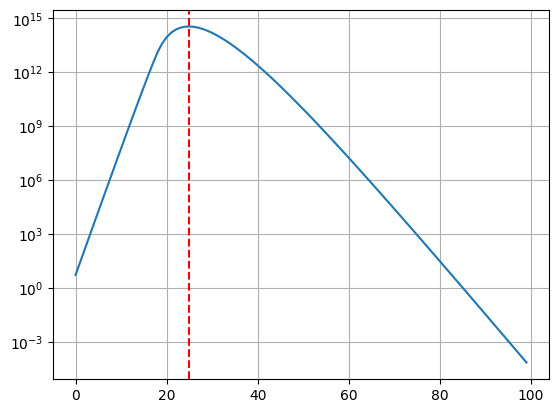

In [4]:
def zad4():
    x_0 = np.ones(20)
    B = np.diag(np.arange(1, 21) * 0.025) + np.diag(np.full(19, 5.0), k=1)

    smallest_k = False

    x_list = []
    x_k = x_0
    for k in range(1,101):
        x_k = B @ x_k
        if np.linalg.norm(x_k)/np.linalg.norm(x_0) < 1 and not smallest_k:
            smallest_k = k
        x_list.append(np.linalg.norm(x_k)/np.linalg.norm(x_0))

    return x_list, smallest_k    


k = np.arange(100)
x_list, smallest_k = zad4()
print(smallest_k)
plt.plot(k,x_list)
plt.axvline(25,linestyle = '--', c = 'red')
plt.yscale('log')
plt.grid()
plt.show()